In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import pprint
import optuna
import joblib

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    roc_auc_score, f1_score, precision_score, 
    recall_score, accuracy_score
)
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier, early_stopping, log_evaluation
from xgboost import XGBClassifier

from IPython.display import display

# Tắt log verbose của Optuna (chỉ hiện summary)
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [2]:
train = pd.read_csv('data/processed/train_preprocessed.csv')
test = pd.read_csv('data/processed/test_preprocessed.csv')

In [3]:
train.head()

,Gender,Age,City,Working Professional or Student,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,...,stress_per_hour,is_working_professional,age_x_workload,Is_Sleep_Deprived,CGPA_Low,Stress_Load,Suicidal_x_FinStress,age_bin,hours_bin,financial_stress_bin
0,0,0.695360,0.186035,1,0.047389,-0.446459,1.495218,-0.486345,-0.441965,-0.221397,...,0.310838,1,-1.142267,0,0,-1.487437,-0.831565,3,0,0
1,1,-1.161867,0.137781,1,0.055411,-0.446459,0.919263,-0.486345,-0.441965,0.354580,...,-0.387219,1,-0.374555,1,0,0.158266,0.788517,1,2,1
2,1,-0.596624,0.159042,0,0.583102,3.136517,-1.384554,2.386461,1.071869,-1.373352,...,-0.526831,0,-0.853654,1,0,-1.487437,-0.291538,1,0,0
3,1,-1.484863,0.130730,1,0.053929,-0.446459,1.495218,-0.486345,-0.441965,-0.797375,...,-0.704518,1,-0.155209,1,0,-0.047447,-0.291538,0,3,0
4,0,-0.838871,0.121874,1,0.053828,-0.446459,-0.808600,-0.486345,-0.441965,-0.797375,...,-0.359297,1,0.133404,1,0,0.981117,1.328544,1,2,1


# 1. Chiến Lược Feature Selection: Lọc Nhiễu và Khử Đa Cộng Tuyến

## Giai đoạn 1: Lọc Nhiễu bằng Tương quan Mục tiêu (Target Correlation Filter)
- **Cách hoạt động:** Thuật toán tính toán hệ số tương quan Pearson giữa từng đặc trưng (feature) và biến mục tiêu (Depression). Trị tuyệt đối (absolute value) được sử dụng để đánh giá sức mạnh của mối quan hệ, bất kể đó là tương quan thuận (dương) hay tương quan nghịch (âm).

- **Tiêu chí loại bỏ:** Thiết lập một ngưỡng tối thiểu (min_target_corr = 0.02). Bất kỳ biến nào có độ tương quan thấp hơn ngưỡng này sẽ bị coi là nhiễu (noise) và bị loại bỏ.

- **Ý nghĩa:** Trong thực tế, nhiều trường dữ liệu được thu thập không mang lại bất kỳ giá trị dự đoán nào. Việc lọc ngưỡng giúp "thanh lọc" tập dữ liệu ngay từ đầu, giảm thiểu rủi ro mô hình cố gắng tìm kiếm quy luật từ những con số ngẫu nhiên, đồng thời giảm tải khối lượng tính toán cho các bước sau.

## Giai đoạn 2: Lọc Đa Cộng Tuyến Thông Minh (Smart Multicollinearity Filter)
- **Cách hoạt động:** Thuật toán xây dựng một ma trận tương quan giữa các đặc trưng (chỉ tính những biến đã lọt qua Giai đoạn 1) với nhau, không bao gồm biến mục tiêu. Mục đích là tìm ra các cặp biến có độ tương quan nội bộ rất cao (ngưỡng max_feature_corr = 0.85).

- **Điểm sáng của thuật toán (Smart Tie-breaker):** Thay vì xóa ngẫu nhiên một biến trong cặp trùng lặp, thuật toán sẽ so sánh lại sức mạnh dự đoán của chúng ở Giai đoạn 1. Biến nào có độ tương quan với mục tiêu thấp hơn sẽ bị loại bỏ; biến nào mang lại tín hiệu mạnh hơn sẽ được giữ lại.

- **Ý nghĩa:** Hiện tượng đa cộng tuyến (Multicollinearity) xảy ra khi hai biến mang chung một lượng thông tin (ví dụ: overall_pressure và Work Pressure). Việc đưa cả hai vào mô hình không làm tăng độ chính xác mà chỉ gây rối loạn trọng số (weights) và làm sai lệch bảng xếp hạng mức độ quan trọng của đặc trưng (Feature Importance). Cách xử lý "chọn lọc" này đảm bảo chúng ta triệt tiêu được sự trùng lặp mà không vô tình vứt bỏ một đặc trưng quan trọng.

Tổng số features ban đầu: 35

--- BƯỚC 1: LỌC TƯƠNG QUAN VỚI LABEL ---
Giữ lại 33 biến có tương quan >= 0.02
Loại bỏ 2 biến nhiễu: ['Family History of Mental Illness', 'Gender']



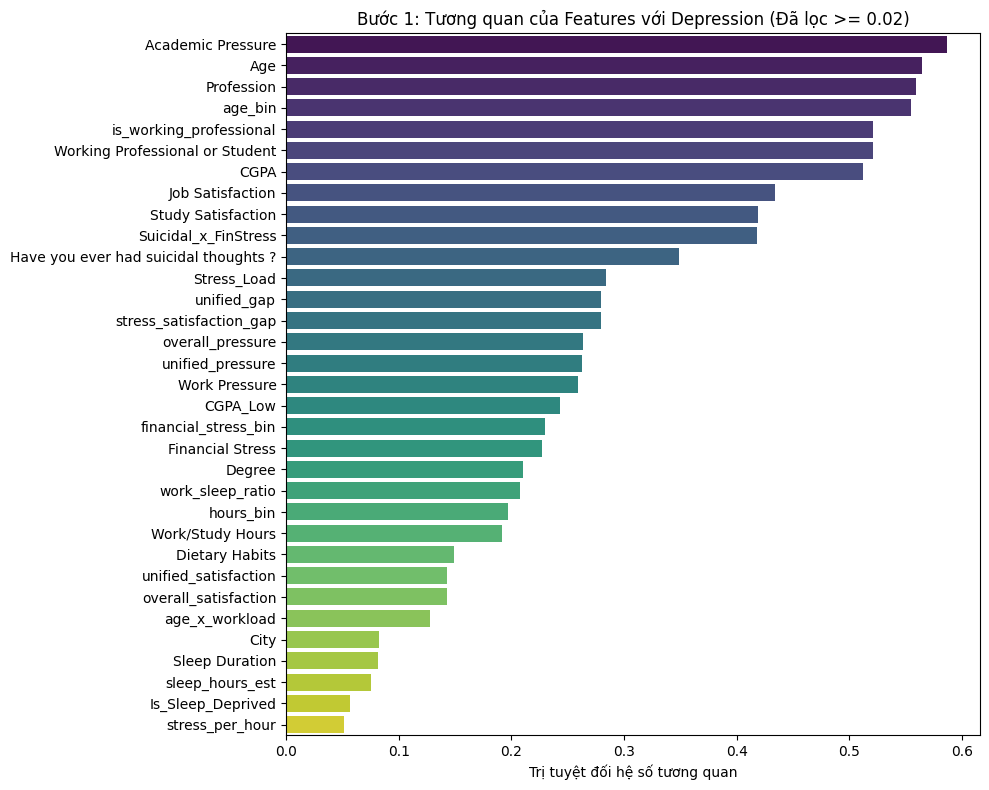

--- BƯỚC 2: LỌC ĐA CỘNG TUYẾN ---
Cặp (age_bin & Age) tương quan 0.98. Xóa 'age_bin' vì dự đoán Target kém hơn.
Cặp (is_working_professional & Academic Pressure) tương quan 0.90. Xóa 'is_working_professional' vì dự đoán Target kém hơn.
Cặp (Working Professional or Student & Academic Pressure) tương quan 0.90. Xóa 'Working Professional or Student' vì dự đoán Target kém hơn.
Cặp (CGPA & Academic Pressure) tương quan 0.88. Xóa 'CGPA' vì dự đoán Target kém hơn.
Cặp (stress_satisfaction_gap & unified_gap) tương quan 1.00. Xóa 'stress_satisfaction_gap' vì dự đoán Target kém hơn.
Cặp (unified_pressure & overall_pressure) tương quan 1.00. Xóa 'unified_pressure' vì dự đoán Target kém hơn.
Cặp (Financial Stress & financial_stress_bin) tương quan 0.95. Xóa 'Financial Stress' vì dự đoán Target kém hơn.
Cặp (hours_bin & work_sleep_ratio) tương quan 0.87. Xóa 'hours_bin' vì dự đoán Target kém hơn.
Cặp (Work/Study Hours & work_sleep_ratio) tương quan 0.90. Xóa 'Work/Study Hours' vì dự đoán Target kém

In [4]:

target_col = 'Depression'


print(f"Tổng số features ban đầu: {train.shape[1] - 1}\n")

# BƯỚC 1: LỌC TƯƠNG QUAN VỚI LABEL (TARGET)
print("--- BƯỚC 1: LỌC TƯƠNG QUAN VỚI LABEL ---")
min_target_corr = 0.02  # Ngưỡng tối thiểu. Dưới mức này coi như là nhiễu (noise)

# Tính độ tương quan của tất cả features với Depression
target_corr = train.corr()[target_col].drop(target_col)
target_corr_abs = target_corr.abs().sort_values(ascending=False)

# Lọc ra các biến đạt tiêu chuẩn
features_step_1 = target_corr_abs[target_corr_abs >= min_target_corr].index.tolist()
dropped_step_1 = target_corr_abs[target_corr_abs < min_target_corr].index.tolist()

print(f"Giữ lại {len(features_step_1)} biến có tương quan >= {min_target_corr}")
print(f"Loại bỏ {len(dropped_step_1)} biến nhiễu: {dropped_step_1}\n")

# Vẽ biểu đồ Top Features
plt.figure(figsize=(10, 8))
sns.barplot(
    x=target_corr_abs[features_step_1].values, 
    y=features_step_1, 
    hue=features_step_1, 
    palette='viridis', 
    legend=False
)
plt.title(f'Bước 1: Tương quan của Features với {target_col} (Đã lọc >= {min_target_corr})')
plt.xlabel('Trị tuyệt đối hệ số tương quan')
plt.tight_layout()
plt.show()

# Tạo dataframe mới chỉ chứa các features đã qua Bước 1
train_step_1 = train[features_step_1 + [target_col]]


# BƯỚC 2: LỌC ĐA CỘNG TUYẾN (MULTICOLLINEARITY)
print("--- BƯỚC 2: LỌC ĐA CỘNG TUYẾN ---")
max_feature_corr = 0.85  # Ngưỡng đa cộng tuyến. Cặp nào >= mức này sẽ bị xử lý

# Tính ma trận tương quan chỉ giữa các features (không có target)
corr_matrix = train_step_1.drop(columns=[target_col]).corr().abs()

# Lấy nửa trên của ma trận để tránh lặp (A-B và B-A)
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

features_to_drop_step_2 = []

# Duyệt qua các cặp có tương quan cao
for column in upper.columns:
    high_corr_vars = upper[column][upper[column] >= max_feature_corr].index.tolist()
    for high_corr_var in high_corr_vars:
        # Nếu cặp này chưa bị loại bỏ ở các vòng lặp trước
        if column not in features_to_drop_step_2 and high_corr_var not in features_to_drop_step_2:
            # Thuật toán thông minh: So sánh độ tương quan với Target
            corr_A_with_target = target_corr_abs[column]
            corr_B_with_target = target_corr_abs[high_corr_var]
            
            # Giữ lại biến tốt hơn, đưa biến kém hơn vào danh sách xóa
            if corr_A_with_target < corr_B_with_target:
                features_to_drop_step_2.append(column)
                print(f"Cặp ({column} & {high_corr_var}) tương quan {upper[column][high_corr_var]:.2f}. Xóa '{column}' vì dự đoán Target kém hơn.")
            else:
                features_to_drop_step_2.append(high_corr_var)
                print(f"Cặp ({column} & {high_corr_var}) tương quan {upper[column][high_corr_var]:.2f}. Xóa '{high_corr_var}' vì dự đoán Target kém hơn.")

# Xóa các biến trùng lặp
final_features = [col for col in features_step_1 if col not in features_to_drop_step_2]

print(f"\nLoại bỏ {len(features_to_drop_step_2)} biến do đa cộng tuyến: {features_to_drop_step_2}")
print(f"Số lượng features CHỐT CUỐI CÙNG: {len(final_features)}\n")



# LƯU KẾT QUẢ ĐỂ ĐƯA VÀO MODEL
X_train_final = train[final_features]
y_train_final = train[target_col]
X_test_final = test[final_features]

print("--- HOÀN TẤT ---")
print(f"Kích thước X_train đưa vào mô hình: {X_train_final.shape}")

# 2. Xử lí mất cân bằng nhãn (Label imbalance)

Mặc dù tập dữ liệu có sự chênh lệch giữa hai lớp, nhưng tỉ lệ này (khoảng 4.5:1) chưa đạt mức cực đoan để bắt buộc phải áp dụng các kỹ thuật tái lấy mẫu (resampling). Thay vào đó, chúng ta lựa chọn phương pháp gán trọng số lớp (class weight) để điều chỉnh mức độ ưu tiên cho lớp thiểu số. Đồng thời, thay vì sử dụng Accuracy, các thước đo như F1-score, Precision và Recall sẽ được ưu tiên để đánh giá hiệu năng mô hình một cách khách quan và chính xác hơn trên dữ liệu mất cân bằng.


## 2.1 Cái bẫy của Accuracy (Độ chính xác tổng thể)

Giả sử tập dữ liệu có 95 người khỏe mạnh (0) và 5 người trầm cảm (1). Một mô hình tồi tệ chỉ cần nhắm mắt đoán tất cả là 0 thì Accuracy vẫn đạt mức khổng lồ $95\%$. Tuy nhiên, mô hình này vô giá trị vì nó bỏ sót 100% bệnh nhân trầm cảm. Do đó, tuyệt đối không dùng Accuracy cho dữ liệu mất cân bằng.

## 2.2 Các Metrics thay thế (Dựa trên Confusion Matrix)

Chúng ta cần tập trung vào nhóm thiểu số (Nhãn 1 - Positive) thông qua các chỉ số sau:

- Precision (Độ chuẩn xác): Trong tất cả những người mô hình dự đoán là có trầm cảm, bao nhiêu người thực sự bị?$$Precision = \frac{TP}{TP + FP}$$

- Recall (Độ phủ / Độ nhạy): Trong tất cả những người bị trầm cảm thực sự trong dữ liệu, mô hình tìm ra được bao nhiêu người?
$$Recall = \frac{TP}{TP + FN}$$

- F1-Score: Là trung bình điều hòa của Precision và Recall, giúp cân bằng cả 2 yếu tố trên.$$F1 = 2 \times \frac{Precision \times Recall}{Precision + Recall}$$

- ROC-AUC: Đo lường khả năng phân tách giữa 2 lớp của mô hình ở mọi ngưỡng xác suất (thresholds). Điểm AUC là $0.5$ nghĩa là mô hình đoán bừa, điểm $1.0$ là hoàn hảo.

## 2.3 Giải pháp kỹ thuật: Trọng số Lớp (Class Weight)
Nguyên lý đơn giản: Phạt mô hình nặng hơn khi nó đoán sai nhãn thiểu số.

- Nếu đoán sai 1 người khỏe mạnh (Nhãn 0): Mô hình bị trừ 1 điểm.

- Nếu đoán sai 1 người trầm cảm (Nhãn 1): Mô hình bị trừ 5 điểm (hoặc 10 điểm tùy độ chênh lệch).

Nhờ sự "đe dọa" này, mô hình buộc phải chú ý vào việc học các đặc trưng của người trầm cảm.

In [5]:
X_test_final.shape, y_train_final.shape, X_train_final.shape

((93800, 21), (140700,), (140700, 21))

# 3. Ba Pipeline Huấn Luyện Chính

Toàn bộ quá trình huấn luyện mô hình được tổ chức thành **3 pipeline** khép kín, chạy tuần tự. Mỗi pipeline đảm nhận một vai trò riêng biệt trong chuỗi xử lý từ dữ liệu đầu vào đến kết quả dự đoán cuối cùng.

```mermaid
flowchart TD
    A["X_train_final, y_train_final"] --> B["Pipeline 1: Optuna Tuning"]
    B --> C["Pipeline 2: K-Fold Evaluation + Ensemble"]
    C --> D["Pipeline 3: OOF Threshold + Retrain + Prediction"]
    D --> E["submission.csv"]
```

---

## Pipeline 1 — Optuna Hyperparameter Tuning

### Mục tiêu
Tự động tìm bộ siêu tham số (hyperparameters) tối ưu cho **4 base models** bằng framework Optuna, thay vì chỉnh tay hoặc dùng Grid/Random Search truyền thống.

### Cơ chế hoạt động

```
┌─────────────────────────────────────────────────┐
│          Optuna Tuning (n_trials × k folds)     │
│                                                 │
│  Trial 1: Optuna đề xuất bộ tham số #1          │
│     └─► Stratified K-Fold CV → Mean AUC         │
│  Trial 2: Optuna đề xuất bộ tham số #2          │
│     └─► Stratified K-Fold CV → Mean AUC         │
│  ...                                            │
│  Trial N: Optuna đề xuất bộ tham số #N          │
│     └─► Stratified K-Fold CV → Mean AUC         │
│                                                 │
│  ► Chọn bộ tham số có Mean AUC cao nhất         │
└─────────────────────────────────────────────────┘
                    │
                    ▼
            best_params_all
        (dict chứa best params cho mỗi model)
```

### Chi tiết từng bước


1. **Vòng lặp chính:** Với mỗi model trong danh sách `[XGBoost, Random Forest, CatBoost, LightGBM]`:
   - Optuna tạo một **study** với hướng tối ưu `maximize` (tối đa hóa AUC).
   - Mỗi **trial**, Optuna đề xuất một bộ tham số từ không gian tìm kiếm được định nghĩa trước:

### Danh sách tham số mô hình

| Model | Tham số được tune |
|---|---|
| **XGBoost** | `learning_rate`, `max_depth`, `min_child_weight`, `subsample`, `colsample_bytree`, `gamma`, `reg_alpha`, `reg_lambda` |
| **Random Forest** | `n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf` |
| **CatBoost** | `learning_rate`, `depth`, `l2_leaf_reg` |
| **LightGBM** | `learning_rate`, `num_leaves`, `min_child_samples`, `subsample`, `colsample_bytree`, `reg_alpha`, `reg_lambda` |

   - Với bộ tham số được đề xuất, tiến hành **Stratified K-Fold Cross-Validation** (k=3 hoặc k=5), tính Mean AUC trên các fold validation.
   - Các model Boosting (XGBoost, CatBoost, LightGBM) được hỗ trợ **early stopping** trong mỗi fold để tránh overfitting.

2. **Đầu ra:** Dictionary `best_params_all` chứa bộ siêu tham số tốt nhất cho từng model.

3. **Xây dựng models dict:** Dùng hàm `build_models_from_tuned_params()` để tạo các model instances sẵn sàng cho Pipeline 2.

### Tại sao Ensemble không cần Optuna?

- **Soft Voting:** Không có tham số — chỉ trung bình đều xác suất.
- **Weighted Voting:** Trọng số tính tự động từ AUC của từng base model.
- **Stacking (LR):** Logistic Regression đủ đơn giản cho 4 cột meta-features; tune thêm dễ overfit.

---

## Pipeline 2 — Stratified K-Fold Evaluation + Ensemble

### Mục tiêu
Đánh giá công bằng **4 base models** + **3 phương pháp ensemble** bằng Stratified K-Fold, đồng thời thu thập **OOF predictions** để phục vụ Stacking và Threshold Search ở Pipeline 3.

### Cơ chế hoạt động

```
        [X_train_final, y_train_final]
                        │
                        ▼
┌───────────────────────────────────────────────────┐
│  Giai đoạn A: Stratified K-Fold (k=5)             │
│  ┌──────────┐ ┌──────┐ ┌──────────┐ ┌──────────┐  │
│  │ XGBoost  │ │  RF  │ │CatBoost  │ │ LightGBM │  │
│  └────┬─────┘ └──┬───┘ └────┬─────┘ └────┬─────┘  │
│       └──────────┴──────────┴────────────┘        │
│           OOF Predictions (xác suất cho mỗi mẫu)  │
└───────────────────────────────────────────────────┘
                        │
                        ▼
    ┌─────────────────────────────────────────┐
    │  Giai đoạn B: Ensemble Methods          │
    │  ├── Soft Voting (trung bình đều)       │
    │  ├── Weighted Voting (theo AUC)         │
    │  └── Stacking — Meta-learner (LR)       │
    └─────────────────────────────────────────┘
                        │
                        ▼
    ┌─────────────────────────────────────────┐
    │  Giai đoạn C: Bảng xếp hạng & Chọn      │
    │  model tốt nhất theo ROC-AUC OOF        │
    └─────────────────────────────────────────┘
```

### Giai đoạn A — Base Models + Out-of-Fold (OOF)

**Tại sao dùng Stratified K-Fold?**

Tập dữ liệu có sự mất cân bằng nhãn (≈18.2% trầm cảm vs ≈81.8% không trầm cảm). `StratifiedKFold` đảm bảo **mỗi fold đều phản ánh đúng tỉ lệ gốc**, từ đó cho kết quả đánh giá ổn định và tin cậy hơn K-Fold thường.

**Cơ chế OOF:**

Ở mỗi vòng fold:
- Model train trên 4 phần, validate trên 1 phần còn lại.
- Xác suất dự đoán trên phần validation được lưu vào vector `oof_probs`.
- Sau 5 fold, `oof_probs` chứa dự đoán cho **toàn bộ tập train** — mỗi dòng được dự đoán bởi model **chưa từng thấy** nó → **không bị data leakage**.

**Metrics theo dõi:** ROC-AUC (chính), Accuracy, F1-Score, Precision, Recall — đo trên từng fold, báo cáo Mean ± Std.

**Kỹ thuật riêng cho từng model:**
- **XGBoost, CatBoost, LightGBM:** Sử dụng `eval_set` + `early_stopping` trong mỗi fold để dừng sớm khi AUC không cải thiện.
- **Random Forest:** Train trực tiếp (không có early stopping vì các cây học độc lập).

### Giai đoạn B — Ensemble Methods

Sau khi thu OOF predictions của 4 base models, pipeline xây dựng **3 phương pháp ensemble**:

#### Soft Voting (Trung bình đều)

$$\hat{p}_{soft} = \frac{1}{M} \sum_{m=1}^{M} \hat{p}_m$$

Trung bình xác suất đồng đều từ $M=4$ model. Không giả định model nào tốt hơn — baseline ensemble đơn giản nhất.

#### Weighted Soft Voting (Trung bình có trọng số)

$$\hat{p}_{weighted} = \sum_{m=1}^{M} w_m \cdot \hat{p}_m, \quad w_m = \frac{\text{AUC}_m}{\sum_{j} \text{AUC}_j}$$

Trọng số $w_m$ tỉ lệ thuận với mean AUC qua 5 fold. Model mạnh hơn đóng góp nhiều hơn.

#### Stacking — Meta-Learner (Logistic Regression)

**Bước 1 — Tạo meta-features:** OOF predictions → ma trận `(n_train, 4)`.

**Bước 2 — Train meta-learner bằng K-Fold lần 2:** LR cũng train bằng `StratifiedKFold(k=5)` trên meta-features để tránh leakage ở tầng 2.

$$\hat{p}_{stack} = \sigma\left(\beta_0 + \sum_{m=1}^{4} \beta_m \cdot \hat{p}_m^{OOF}\right)$$

**Tại sao dùng LR làm meta-learner?** Meta-features (4 cột xác suất) tương quan cao → LR đủ đơn giản để chỉ học trọng số tuyến tính tối ưu mà không overfit.

### Giai đoạn C — Xếp hạng & Chọn Best

`results_df` tổng hợp tất cả 7 model/ensemble, sắp xếp theo **ROC-AUC** giảm dần. Model có AUC cao nhất trên OOF được chọn để chuyển sang Pipeline 3.

**Tại sao dùng ROC-AUC làm tiêu chí chính?** AUC đo lường **khả năng phân tách** ở mọi ngưỡng xác suất — không phụ thuộc vào threshold cố định 0.5.

---

## Pipeline 3 — OOF Threshold Search + Retrain + Prediction

### Mục tiêu
Tìm ngưỡng phân loại tối ưu (thay vì mặc định 0.5), retrain model tốt nhất trên toàn bộ tập train, và tạo file submission cho tập test.

### Cơ chế hoạt động

```
┌────────────────────────────────────────────────┐
│  Bước 1: Chọn Best Model từ Pipeline 2         │
│  (Model/Ensemble có ROC-AUC OOF cao nhất)      │
└────────────────────────────────────────────────┘
                        │
                        ▼
┌────────────────────────────────────────────────┐
│  Bước 2: OOF Threshold Search                  │
│  Quét threshold từ 0.10 → 0.89 (bước 0.01)     │
│  Chọn threshold tối đa hóa F1-Score trên OOF   │
└────────────────────────────────────────────────┘
                        │
                        ▼
┌────────────────────────────────────────────────┐
│  Bước 3: Retrain trên tập Train                │
│  85% Train → fit() với early_stopping          │
│  15% Val   → eval_set để dừng sớm              │
└────────────────────────────────────────────────┘
                        │
                        ▼
┌────────────────────────────────────────────────┐
│  Bước 4: Dự đoán tập Test                      │
│  predict_proba() → áp threshold tối ưu → 0/1   │
│  Xuất file submission.csv                      │
└────────────────────────────────────────────────┘
```

### Bước 1 — Chọn Best Model

Dựa trên bảng xếp hạng `results_df` từ Pipeline 2, lấy model/ensemble ở vị trí đầu tiên (AUC cao nhất).

### Bước 2 — OOF Threshold Search

**Tại sao không dùng ngưỡng mặc định 0.5?**

Với dữ liệu mất cân bằng (≈18%/82%), model có xu hướng cho xác suất thấp cho nhãn thiểu số → dùng 0.5 sẽ **bỏ sót nhiều người trầm cảm** (Recall thấp).

**Tại sao dùng OOF thay vì 15% validation?**
- OOF dùng **toàn bộ** tập train (~140K mẫu), mỗi mẫu được dự đoán bởi model **chưa từng thấy** nó → **không bị data leakage**.
- 15% validation chỉ có ~21K mẫu → kém ổn định hơn.

**Quy trình:**
1. Quét `threshold` từ 0.10 đến 0.89, bước 0.01.
2. Với mỗi threshold, chuyển OOF probabilities → nhãn 0/1, tính F1-Score.
3. Chọn threshold tối đa hóa F1-Score → `best_threshold`.

**Báo cáo tại ngưỡng tối ưu:** F1-Score, Precision, Recall, Accuracy, AUC.

### Bước 3 — Retrain Best Model

**Trường hợp Best là Single Model:**
- Tạo lại model instance với best params từ Optuna (Pipeline 1).
- Chia tập train thành 85% train + 15% validation.
- Fit model trên 85%, dùng 15% làm `eval_set` cho early stopping.
- Giữ lại checkpoint tốt nhất (`use_best_model=True`).

**Trường hợp Best là Ensemble:**
- Retrain **tất cả 4 base models** theo cùng cách trên.
- Dự đoán test probabilities cho mỗi base model.
- Áp dụng phương pháp ensemble tương ứng:
  - **Soft Voting:** trung bình đều.
  - **Weighted Voting:** trọng số theo AUC.
  - **Stacking (LR):** retrain meta-learner trên OOF, rồi predict.

### Bước 4 — Dự đoán & Xuất kết quả

```python
test_probs = best_model.predict_proba(X_test_final)[:, 1]
test_predictions = (test_probs >= best_threshold).astype(int)
```

- Áp dụng `best_threshold` (từ Bước 2) thay vì 0.5.
- Lưu model + threshold vào file `.pkl` để sử dụng sau.
- Xuất file `submission.csv` chứa nhãn dự đoán 0/1.


**Pipeline 1 — Optuna Hyperparameter Tuning**

In [ ]:
#  HÀM OPTUNA TUNING 

def optuna_tune_all_models(X, y, n_splits=3, n_trials=20, random_state=42):
    """
    Tự động tuning hyperparameters cho 4 base models bằng Optuna.

    Cơ chế:
    - Mỗi trial, Optuna đề xuất 1 bộ tham số
    - Đánh giá bằng Stratified K-Fold OOF AUC (mean)
    - Sau n_trials, trả về bộ tham số tốt nhất cho từng model

    Ensemble (Soft/Weighted Voting, Stacking) KHÔNG cần Optuna vì:
    - Soft Voting: không có tham số
    - Weighted Voting: trọng số tính tự động từ AUC
    - Stacking (LR): LR đủ đơn giản, tune thêm dễ overfit 4 cột meta-features
    """

    pos_count = (y == 1).sum()
    neg_count = (y == 0).sum()
    scale_pos_weight = float(neg_count / max(pos_count, 1))

    best_params_all = {}
    model_names = ["XGBoost", "Random Forest", "CatBoost", "LightGBM"]

    for model_name in model_names:
        print(f"\n{'='*60}")
        print(f" OPTUNA TUNING: {model_name} ({n_trials} trials × {n_splits} folds)")
        print(f"{'='*60}")

        start_time = time.time()

        def objective(trial):
            kf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
            fold_aucs = []

            # ── Đề xuất tham số tùy theo model ──
            if model_name == "XGBoost":
                params = {
                    'learning_rate': trial.suggest_float('learning_rate', 0.05, 0.1, log=True),
                    'max_depth': trial.suggest_int('max_depth', 4, 8),
                    'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
                    'subsample': trial.suggest_float('subsample', 0.6, 1.0),
                    'colsample_bytree': trial.suggest_float('colsample_bytree', 0.2, 0.4),
                    'gamma': trial.suggest_float('gamma', 0, 5),
                    'reg_alpha': trial.suggest_float('reg_alpha', 0.001, 1.0, log=True),
                    'reg_lambda': trial.suggest_float('reg_lambda', 0.001, 1.0, log=True),
                }
                clf_template = XGBClassifier(
                    objective='binary:logistic', eval_metric='auc',
                    n_estimators=1000, scale_pos_weight=scale_pos_weight,
                    tree_method='hist', random_state=random_state,
                    n_jobs=-1, verbosity=0, early_stopping_rounds=100,
                    **params
                )

            elif model_name == "Random Forest":
                params = {
                    'n_estimators': 50,
                    'max_depth': trial.suggest_int('max_depth', 5, 20),
                    'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
                    'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
                }
                clf_template = RandomForestClassifier(
                    class_weight='balanced', random_state=random_state,
                    **params
                )

            elif model_name == "CatBoost":
                params = {
                    'learning_rate': trial.suggest_float('learning_rate', 0.05, 0.1, log=True),
                    'depth': trial.suggest_int('depth', 4, 10),
                    'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1, 10),
                }
                clf_template = CatBoostClassifier(
                    iterations=2000, auto_class_weights='Balanced',
                    eval_metric='AUC', early_stopping_rounds=100,
                    verbose=0, random_state=random_state,
                    **params
                )

            elif model_name == "LightGBM":
                params = {
                    'learning_rate': trial.suggest_float('learning_rate', 0.05, 0.1, log=True),
                    'num_leaves': trial.suggest_int('num_leaves', 15, 50),
                    'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
                    'subsample': trial.suggest_float('subsample', 0.6, 1.0),
                    'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
                    'reg_alpha': trial.suggest_float('reg_alpha', 0.001, 1.0, log=True),
                    'reg_lambda': trial.suggest_float('reg_lambda', 0.001, 1.0, log=True),
                }
                clf_template = LGBMClassifier(
                    objective='binary', n_estimators=2000,
                    class_weight='balanced', random_state=random_state,
                    verbosity=-1,
                    **params
                )

            # ── Chạy K-Fold CV ──
            for fold, (train_idx, val_idx) in enumerate(kf.split(X, y)):
                X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
                X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]

                clf = clone(clf_template)

                if isinstance(clf, LGBMClassifier):
                    clf.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], eval_metric='auc',
                            callbacks=[early_stopping(50, verbose=False), log_evaluation(0)])
                elif isinstance(clf, XGBClassifier):
                    clf.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
                elif isinstance(clf, CatBoostClassifier):
                    clf.fit(X_tr, y_tr, eval_set=(X_va, y_va), use_best_model=True, verbose=False)
                else:
                    clf.fit(X_tr, y_tr)

                val_prob = clf.predict_proba(X_va)[:, 1]
                fold_aucs.append(roc_auc_score(y_va, val_prob))

            return np.mean(fold_aucs)

        # ── Chạy Optuna study ──
        study = optuna.create_study(direction='maximize',
                                     study_name=f'{model_name}_tuning')
        study.optimize(objective, n_trials=n_trials, show_progress_bar=True)

        elapsed = time.time() - start_time
        best_params_all[model_name] = study.best_params

        print(f"\n Best AUC (CV mean): {study.best_value:.4f}")
        print(f" Thời gian: {elapsed:.1f}s")
        print(f" Best params:")
        for k, v in study.best_params.items():
            print(f"   {k}: {v}")

    return best_params_all


def build_models_from_tuned_params(best_params_all, scale_pos_weight, random_state=42):
    """
    Tạo dict models từ best params của Optuna.
    """
    models = {}

    if "XGBoost" in best_params_all:
        models["XGBoost"] = XGBClassifier(
            objective='binary:logistic', eval_metric='auc',
            n_estimators=1000, scale_pos_weight=scale_pos_weight,
            tree_method='hist', random_state=random_state,
            n_jobs=-1, verbosity=0, early_stopping_rounds=100,
            **best_params_all["XGBoost"]
        )

    if "Random Forest" in best_params_all:
        models["Random Forest"] = RandomForestClassifier(
            class_weight='balanced', random_state=random_state,
            **best_params_all["Random Forest"]
        )

    if "CatBoost" in best_params_all:
        models["CatBoost"] = CatBoostClassifier(
            iterations=2000, auto_class_weights='Balanced',
            eval_metric='AUC', early_stopping_rounds=100,
            verbose=100, random_state=random_state,
            **best_params_all["CatBoost"]
        )

    if "LightGBM" in best_params_all:
        models["LightGBM"] = LGBMClassifier(
            objective='binary', n_estimators=2000,
            class_weight='balanced', random_state=random_state,
            verbosity=-1,
            **best_params_all["LightGBM"]
        )

    return models



# Tính scale_pos_weight
pos_count = (y_train_final == 1).sum()
neg_count = (y_train_final == 0).sum()
scale_pos_weight = float(neg_count / max(pos_count, 1))

# Chạy Optuna tuning cho tất cả models
best_params_all = optuna_tune_all_models(
    X_train_final, y_train_final,
    n_splits=3,
    n_trials=20,   
    random_state=42
)

# Tạo models dict từ best params
models = build_models_from_tuned_params(best_params_all, scale_pos_weight)



 OPTUNA TUNING: XGBoost (20 trials × 3 folds)


Best trial: 15. Best value: 0.975303: 100%|██████████| 20/20 [16:25<00:00, 49.25s/it]



 Best AUC (CV mean): 0.9753
 Thời gian: 985.1s
 Best params:
   learning_rate: 0.057015911329870134
   max_depth: 6
   min_child_weight: 9
   subsample: 0.902626903350691
   colsample_bytree: 0.20192971500222584
   gamma: 4.887316308978147
   reg_alpha: 0.3566489700191325
   reg_lambda: 0.05190652117963112

 OPTUNA TUNING: Random Forest (20 trials × 3 folds)


Best trial: 18. Best value: 0.97281: 100%|██████████| 20/20 [12:13<00:00, 36.68s/it]



 Best AUC (CV mean): 0.9728
 Thời gian: 733.6s
 Best params:
   max_depth: 12
   min_samples_split: 13
   min_samples_leaf: 10

 OPTUNA TUNING: CatBoost (20 trials × 3 folds)


Best trial: 2. Best value: 0.975351: 100%|██████████| 20/20 [11:17<00:00, 33.86s/it]



 Best AUC (CV mean): 0.9754
 Thời gian: 677.3s
 Best params:
   learning_rate: 0.06787154025325526
   depth: 4
   l2_leaf_reg: 7.189987431518505

 OPTUNA TUNING: LightGBM (20 trials × 3 folds)


Best trial: 18. Best value: 0.97503: 100%|██████████| 20/20 [03:14<00:00,  9.70s/it] 


 Best AUC (CV mean): 0.9750
 Thời gian: 194.1s
 Best params:
   learning_rate: 0.06379514097428267
   num_leaves: 15
   min_child_samples: 19
   subsample: 0.8190082926740492
   colsample_bytree: 0.6392844072319408
   reg_alpha: 0.20720561003110768
   reg_lambda: 0.09603313970171992


**Pipeline 2 — Stratified K-Fold Evaluation + Ensemble**


In [ ]:
def evaluate_team_models(models_dict, X, y, n_splits=5, random_state=42, add_ensembles=True):
    """
    Hàm chạy Pipeline xài chung cho toàn bộ các model.
    Hỗ trợ riêng cho LightGBM/XGBoost/CatBoost với early stopping trên từng fold.
    Có thể tự động thêm các ensemble methods từ OOF predictions.
    """

    def _metric_pack(y_true, y_prob, threshold=0.5):
        y_pred = (y_prob >= threshold).astype(int)
        return {
            'auc': roc_auc_score(y_true, y_prob),
            'acc': accuracy_score(y_true, y_pred),
            'f1': f1_score(y_true, y_pred),
            'prec': precision_score(y_true, y_pred),
            'rec': recall_score(y_true, y_pred),
        }

    print("=====================================================")
    print(" BẮT ĐẦU PIPELINE ĐÁNH GIÁ")
    print("=====================================================")
    print(f" Shape của dữ liệu huấn luyện: X = {X.shape}, y = {y.shape}")
    print(f" Tỉ lệ nhãn (0/1): {(y==0).sum()} / {(y==1).sum()}")
    print("-----------------------------------------------------\n")

    kf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)

    results_list = []
    oof_predictions = {}
    mean_auc_by_model = {}
    pp = pprint.PrettyPrinter(indent=4, width=100, compact=True)

    for model_name, model in models_dict.items():
        print(f"Đang huấn luyện: {model_name}...")
        print("Cấu hình tham số đã tinh chỉnh:")

        current_params = model.get_params()

        if isinstance(model, CatBoostClassifier):
            custom_params = {k: v for k, v in current_params.items() if v is not None}
        else:
            try:
                default_model = model.__class__()
                default_params = default_model.get_params()

                custom_params = {
                    k: v for k, v in current_params.items()
                    if k in default_params and current_params[k] != default_params[k]
                }

                # Luôn in các tham số quan trọng cho đọc log
                always_print = [
                    'random_state', 'n_jobs', 'class_weight', 'scale_pos_weight',
                    'eval_metric', 'learning_rate', 'n_estimators', 'max_depth', 'early_stopping_rounds'
                ]
                for key in always_print:
                    if key in current_params and key not in custom_params:
                        custom_params[key] = current_params[key]

                # Fallback: nếu sau lọc còn quá ít tham số thì in toàn bộ tham số đã set
                if len(custom_params) <= 1:
                    custom_params = {k: v for k, v in current_params.items() if v is not None}

            except Exception:
                custom_params = {k: v for k, v in current_params.items() if v is not None}

        pp.pprint(custom_params)
        print("-----------------------------------------------------")
        start_time = time.time()

        fold_auc, fold_f1, fold_prec, fold_recall, fold_acc = [], [], [], [], []
        oof_probs = np.zeros(len(X))

        for fold, (train_idx, val_idx) in enumerate(kf.split(X, y)):
            X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
            X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]

            clf = clone(model)

            # Các model boosting có thể dùng early stopping nếu có eval_set ở từng fold.
            if isinstance(clf, LGBMClassifier):
                clf.fit(
                    X_tr,
                    y_tr,
                    eval_set=[(X_va, y_va)],
                    eval_metric='auc',
                    callbacks=[
                        early_stopping(stopping_rounds=50, verbose=False),
                        log_evaluation(period=0),
                    ],
                )
            elif isinstance(clf, XGBClassifier):
                clf.fit(
                    X_tr,
                    y_tr,
                    eval_set=[(X_va, y_va)],
                    verbose=False,
                )
            elif isinstance(clf, CatBoostClassifier):
                clf.fit(
                    X_tr,
                    y_tr,
                    eval_set=(X_va, y_va),
                    use_best_model=True,
                    verbose=False,
                )
            else:
                clf.fit(X_tr, y_tr)

            val_prob = clf.predict_proba(X_va)[:, 1]
            val_pred = (val_prob >= 0.5).astype(int)
            oof_probs[val_idx] = val_prob

            auc = roc_auc_score(y_va, val_prob)
            f1 = f1_score(y_va, val_pred)
            prec = precision_score(y_va, val_pred)
            rec = recall_score(y_va, val_pred)
            acc = accuracy_score(y_va, val_pred)

            fold_auc.append(auc)
            fold_f1.append(f1)
            fold_prec.append(prec)
            fold_recall.append(rec)
            fold_acc.append(acc)

            print(f"   - Fold {fold+1}: AUC={auc:.4f} | Acc={acc:.4f} | F1={f1:.4f} | Prec={prec:.4f} | Recall={rec:.4f}")

        elapsed_time = time.time() - start_time
        mean_auc, std_auc = np.mean(fold_auc), np.std(fold_auc)
        mean_auc_by_model[model_name] = mean_auc

        results_list.append({
            'Model': model_name,
            'ROC-AUC (Mean)': f"{mean_auc:.4f} (±{std_auc:.4f})",
            'Accuracy': f"{np.mean(fold_acc):.4f}",
            'F1-Score': np.mean(fold_f1),
            'Precision': np.mean(fold_prec),
            'Recall': np.mean(fold_recall),
            'Time (s)': f"{elapsed_time:.2f}",
            'Raw_AUC_Mean': mean_auc
        })

        oof_predictions[model_name] = oof_probs
        print(f" Hoàn tất {model_name} -> Mean AUC: {mean_auc:.4f}\n")

    # Ensemble methods dựa trên OOF predictions của các model nền
    if add_ensembles and len(oof_predictions) >= 2:
        print("=====================================================")
        print(" TÍCH HỢP ENSEMBLE METHODS")
        print("=====================================================")

        y_arr = y.to_numpy()
        base_model_names = list(oof_predictions.keys())
        oof_matrix = np.column_stack([oof_predictions[name] for name in base_model_names])

        # 1) Soft Voting (trung bình đều)
        start_time = time.time()
        soft_prob = oof_matrix.mean(axis=1)
        soft_m = _metric_pack(y_arr, soft_prob, threshold=0.5)
        soft_elapsed = time.time() - start_time
        oof_predictions['Ensemble - Soft Voting'] = soft_prob

        results_list.append({
            'Model': 'Ensemble - Soft Voting',
            'ROC-AUC (Mean)': f"{soft_m['auc']:.4f} (OOF)",
            'Accuracy': f"{soft_m['acc']:.4f}",
            'F1-Score': soft_m['f1'],
            'Precision': soft_m['prec'],
            'Recall': soft_m['rec'],
            'Time (s)': f"{soft_elapsed:.2f}",
            'Raw_AUC_Mean': soft_m['auc']
        })
        print(f"   - Soft Voting OOF AUC: {soft_m['auc']:.4f}")

        # 2) Weighted Soft Voting (trọng số theo AUC trung bình của base models)
        start_time = time.time()
        base_weights = np.array([mean_auc_by_model[name] for name in base_model_names], dtype=float)
        base_weights = base_weights / base_weights.sum()
        weighted_prob = np.average(oof_matrix, axis=1, weights=base_weights)
        weighted_m = _metric_pack(y_arr, weighted_prob, threshold=0.5)
        weighted_elapsed = time.time() - start_time
        oof_predictions['Ensemble - Weighted Voting'] = weighted_prob

        results_list.append({
            'Model': 'Ensemble - Weighted Voting',
            'ROC-AUC (Mean)': f"{weighted_m['auc']:.4f} (OOF)",
            'Accuracy': f"{weighted_m['acc']:.4f}",
            'F1-Score': weighted_m['f1'],
            'Precision': weighted_m['prec'],
            'Recall': weighted_m['rec'],
            'Time (s)': f"{weighted_elapsed:.2f}",
            'Raw_AUC_Mean': weighted_m['auc']
        })
        print(f"   - Weighted Voting OOF AUC: {weighted_m['auc']:.4f}")

        # 3) Stacking (meta-learner = Logistic Regression, tạo meta-OOF để tránh leakage)
        start_time = time.time()
        stack_oof = np.zeros(len(y_arr))
        meta_kf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)

        for tr_idx, va_idx in meta_kf.split(oof_matrix, y_arr):
            meta_model = LogisticRegression(
                class_weight='balanced',
                random_state=random_state,
                max_iter=1000
            )
            meta_model.fit(oof_matrix[tr_idx], y_arr[tr_idx])
            stack_oof[va_idx] = meta_model.predict_proba(oof_matrix[va_idx])[:, 1]

        stack_m = _metric_pack(y_arr, stack_oof, threshold=0.5)
        stack_elapsed = time.time() - start_time
        oof_predictions['Ensemble - Stacking (LR)'] = stack_oof

        results_list.append({
            'Model': 'Ensemble - Stacking (LR)',
            'ROC-AUC (Mean)': f"{stack_m['auc']:.4f} (OOF)",
            'Accuracy': f"{stack_m['acc']:.4f}",
            'F1-Score': stack_m['f1'],
            'Precision': stack_m['prec'],
            'Recall': stack_m['rec'],
            'Time (s)': f"{stack_elapsed:.2f}",
            'Raw_AUC_Mean': stack_m['auc']
        })
        print(f"   - Stacking (LR) OOF AUC: {stack_m['auc']:.4f}\n")

    results_df = pd.DataFrame(results_list).sort_values(by='Raw_AUC_Mean', ascending=False)
    results_df = results_df.drop(columns=['Raw_AUC_Mean']).reset_index(drop=True)

    print("=====================================================")
    print("BẢNG TỔNG HỢP METRICS CỦA CÁC MODEL + ENSEMBLE")
    print("=====================================================")
    display(results_df)

    return results_df, oof_predictions

In [ ]:


results_df, oof_preds = evaluate_team_models(
    models,
    X_train_final,
    y_train_final,
    add_ensembles=True
)

 BẮT ĐẦU PIPELINE ĐÁNH GIÁ
 Shape của dữ liệu huấn luyện: X = (140700, 21), y = (140700,)
 Tỉ lệ nhãn (0/1): 115133 / 25567
-----------------------------------------------------

Đang huấn luyện: XGBoost...
Cấu hình tham số đã tinh chỉnh:
{   'colsample_bytree': 0.20192971500222584,
    'early_stopping_rounds': 100,
    'eval_metric': 'auc',
    'gamma': 4.887316308978147,
    'learning_rate': 0.057015911329870134,
    'max_depth': 6,
    'min_child_weight': 9,
    'missing': nan,
    'n_estimators': 1000,
    'n_jobs': -1,
    'random_state': 42,
    'reg_alpha': 0.3566489700191325,
    'reg_lambda': 0.05190652117963112,
    'scale_pos_weight': 4.503187702898267,
    'subsample': 0.902626903350691,
    'tree_method': 'hist',
    'verbosity': 0}
-----------------------------------------------------
   - Fold 1: AUC=0.9754 | Acc=0.9177 | F1=0.8039 | Prec=0.7088 | Recall=0.9284
   - Fold 2: AUC=0.9741 | Acc=0.9178 | F1=0.8023 | Prec=0.7126 | Recall=0.9179
   - Fold 3: AUC=0.9752 | Acc=0.

,Model,ROC-AUC (Mean),Accuracy,F1-Score,Precision,Recall,Time (s)
0,CatBoost,0.9754 (±0.0010),0.9177,0.804183,0.708435,0.929870,60.60
1,XGBoost,0.9754 (±0.0009),0.9195,0.807138,0.714913,0.926702,45.45
2,Ensemble - Stacking (LR),0.9753 (OOF),0.9201,0.808324,0.716740,0.926742,1.95
3,Ensemble - Weighted Voting,0.9753 (OOF),0.9205,0.808791,0.718627,0.924825,0.18
4,Ensemble - Soft Voting,0.9753 (OOF),0.9205,0.808805,0.718649,0.924825,0.13
5,LightGBM,0.9751 (±0.0009),0.9177,0.803908,0.709104,0.927993,15.19
6,Random Forest,0.9731 (±0.0012),0.9238,0.812515,0.734931,0.908436,94.65


**Tổng quan:** Tất cả 7 model đều đạt ROC-AUC trên 0.97, khoảng cách giữa model tốt nhất và kém nhất chỉ 0.0023.

- **CatBoost (Hạng 1):** Đạt ROC-AUC cao nhất (0.9754) cùng Recall cao nhất toàn bảng (0.9299) — phát hiện được 93% bệnh nhân trầm cảm. Đây là ưu tiên quan trọng nhất trong bài toán y tế vì hậu quả bỏ sót bệnh nhân (False Negative) nghiêm trọng hơn nhiều so với cảnh báo nhầm. Tuy nhiên, Precision thấp nhất nhóm Boosting (0.7084), tức khoảng 29% cảnh báo nhầm.

- **XGBoost (Hạng 2):** ROC-AUC bằng CatBoost nhưng cân bằng hơn giữa Precision (0.7149) và Recall (0.9267), thể hiện qua F1-Score cao hơn (0.8071 vs 0.8042). Đồng thời có độ ổn định tốt nhất (Std ±0.0009) và thời gian huấn luyện nhanh hơn CatBoost.

- **Nhóm Ensemble (Hạng 3–5):** Cả 3 phương pháp (Stacking, Weighted Voting, Soft Voting) đều đạt AUC 0.9753 — không vượt trội so với base model đơn lẻ. Nguyên nhân: các base model có hiệu năng quá đồng nhất và đều thuộc họ Tree-based, nên tín hiệu bổ sung giữa chúng bị hạn chế. Soft Voting ≈ Weighted Voting vì trọng số AUC của 4 model gần bằng nhau.

- **LightGBM (Hạng 6):** Hiệu năng chỉ kém top 0.0003 AUC nhưng nhanh nhất nhóm base model (15s — nhanh gấp 4× XGBoost), rất phù hợp khi cần thử nghiệm nhanh hoặc tài nguyên hạn chế.

- **Random Forest (Hạng 7):** Có Precision cao nhất (0.7349) và F1-Score cao nhất (0.8125) nhưng AUC thấp nhất (0.9731) và Recall thấp nhất (0.9084). Nghịch lý này do RF ưu tiên "chắc ăn" — khi dự đoán ai bị trầm cảm thì rất chính xác, nhưng bỏ sót nhiều bệnh nhân hơn. Ngoài ra, thời gian chậm nhất (94.65s) do không có cơ chế early stopping.

**Kết Luận**
CatBoost được chọn làm model chính nhờ ROC-AUC và Recall cao nhất — phù hợp nhất với mục tiêu phát hiện tối đa bệnh nhân trầm cảm.

**Pipeline 3 — OOF Threshold Search + Retrain + Prediction**


Best Model/Ensemble: CatBoost

 OOF THRESHOLD SEARCH
 Threshold tối ưu (F1 cao nhất): 0.75
 F1-Score tại ngưỡng tối ưu    : 0.8347


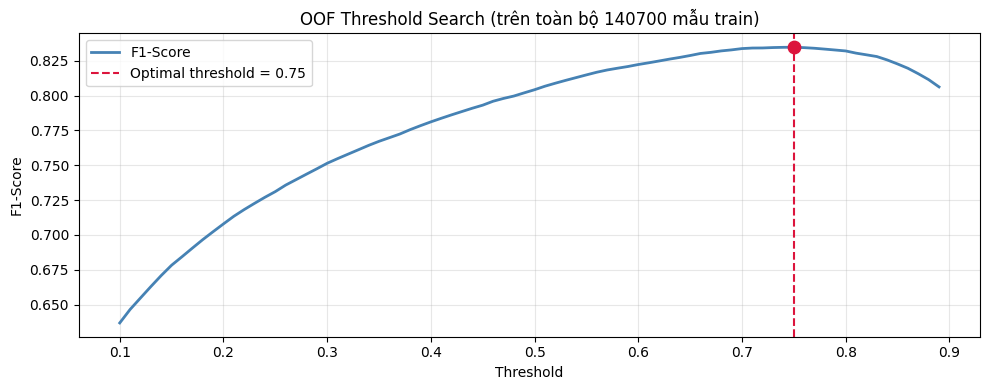


── Báo cáo trên OOF (threshold tối ưu = 0.75) ──
  F1-Score : 0.8347
  Precision: 0.8168
  Recall   : 0.8534
  Accuracy : 0.9386
  AUC      : 0.9754


In [ ]:
# OOF THRESHOLD SEARCH
# Chọn Best Model dựa trên bảng xếp hạng 
# results_df đã sort theo Raw_AUC_Mean giảm dần (index 0 = tốt nhất)
best_model_name = results_df.iloc[0]['Model']
print(f"Best Model/Ensemble: {best_model_name}")


best_oof_probs = oof_preds[best_model_name]
y_arr = y_train_final.to_numpy()

thresholds = np.arange(0.1, 0.9, 0.01)
f1_scores = []

for thr in thresholds:
    preds = (best_oof_probs >= thr).astype(int)
    f1_scores.append(f1_score(y_arr, preds))

best_idx = int(np.argmax(f1_scores))
best_threshold = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

print(f"\n{'='*60}")
print(f" OOF THRESHOLD SEARCH")
print(f"{'='*60}")
print(f" Threshold tối ưu (F1 cao nhất): {best_threshold:.2f}")
print(f" F1-Score tại ngưỡng tối ưu    : {best_f1:.4f}")

# ── Vẽ đồ thị F1 theo Threshold ──
plt.figure(figsize=(10, 4))
plt.plot(thresholds, f1_scores, color='steelblue', linewidth=2, label='F1-Score')
plt.axvline(best_threshold, color='crimson', linestyle='--', linewidth=1.5,
            label=f'Optimal threshold = {best_threshold:.2f}')
plt.scatter([best_threshold], [best_f1], color='crimson', zorder=5, s=80)
plt.xlabel('Threshold')
plt.ylabel('F1-Score')
plt.title(f'OOF Threshold Search (trên toàn bộ {len(y_arr)} mẫu train)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ── Báo cáo metrics tại ngưỡng tối ưu trên OOF ──
oof_preds_optimal = (best_oof_probs >= best_threshold).astype(int)
print(f"\n── Báo cáo trên OOF (threshold tối ưu = {best_threshold:.2f}) ──")
print(f"  F1-Score : {f1_score(y_arr, oof_preds_optimal):.4f}")
print(f"  Precision: {precision_score(y_arr, oof_preds_optimal):.4f}")
print(f"  Recall   : {recall_score(y_arr, oof_preds_optimal):.4f}")
print(f"  Accuracy : {accuracy_score(y_arr, oof_preds_optimal):.4f}")
print(f"  AUC      : {roc_auc_score(y_arr, best_oof_probs):.4f}")





In [ ]:
# RETRAIN BEST MODEL + DỰ ĐOÁN TEST

# Chỉ retrain nếu best model là single model (không phải ensemble)
# Nếu best là ensemble → cần retrain tất cả base models
is_ensemble = "Ensemble" in best_model_name

if not is_ensemble:
    print(f"\n{'='*60}")
    print(f" RETRAIN: {best_model_name}")
    print(f"{'='*60}")

    # Tạo lại model với best params từ Optuna
    final_model_params = best_params_all[best_model_name]

    if best_model_name == "LightGBM":
        best_model = LGBMClassifier(
            objective='binary', n_estimators=2000,
            class_weight='balanced', random_state=42, verbosity=-1,
            **final_model_params
        )
    elif best_model_name == "XGBoost":
        best_model = XGBClassifier(
            objective='binary:logistic', eval_metric='auc',
            n_estimators=1000, scale_pos_weight=scale_pos_weight,
            tree_method='hist', random_state=42, n_jobs=-1,
            verbosity=0, early_stopping_rounds=100,
            **final_model_params
        )
    elif best_model_name == "CatBoost":
        best_model = CatBoostClassifier(
            iterations=2000, auto_class_weights='Balanced',
            eval_metric='AUC', early_stopping_rounds=100,
            verbose=100, random_state=42,
            **final_model_params
        )
    elif best_model_name == "Random Forest":
        best_model = RandomForestClassifier(
            class_weight='balanced', random_state=42,
            **final_model_params
        )

    # Retrain trên 85% + 15% validation cho early stopping
    print("Đang retrain trên 85% tập Train (15% cho early stopping)...")
    X_tr_full, X_val_full, y_tr_full, y_val_full = train_test_split(
        X_train_final, y_train_final,
        test_size=0.15, stratify=y_train_final, random_state=42
    )

    if isinstance(best_model, LGBMClassifier):
        best_model.fit(
            X_tr_full, y_tr_full,
            eval_set=[(X_val_full, y_val_full)],
            eval_metric='auc',
            callbacks=[early_stopping(50, verbose=False), log_evaluation(100)]
        )
        print(f"\nDừng ở iteration: {best_model.best_iteration_}")

    elif isinstance(best_model, XGBClassifier):
        best_model.fit(
            X_tr_full, y_tr_full,
            eval_set=[(X_val_full, y_val_full)],
            verbose=False
        )
        print(f"\nDừng ở iteration: {best_model.best_iteration}")

    elif isinstance(best_model, CatBoostClassifier):
        best_model.fit(
            X_tr_full, y_tr_full,
            eval_set=(X_val_full, y_val_full),
            use_best_model=True, verbose=100
        )
        print(f"\nDừng ở iteration: {best_model.best_iteration_}")

    else:
        # Random Forest — không có early stopping
        best_model.fit(X_tr_full, y_tr_full)
        print("Hoàn tất training (RF không dùng early stopping)")

    # ── Dự đoán test ──
    test_probs = best_model.predict_proba(X_test_final)[:, 1]
    test_predictions = (test_probs >= best_threshold).astype(int)

    print(f"\nThreshold áp dụng: {best_threshold:.2f}")
    print(f"Phân phối nhãn test: 0 → {(test_predictions==0).sum()} | "
          f"1 → {(test_predictions==1).sum()}")

else:
    # ── Xử lý trường hợp Best là Ensemble ──
    print(f"\n{'='*60}")
    print(f" RETRAIN ENSEMBLE: {best_model_name}")
    print(f"{'='*60}")

    # Split cho early stopping
    X_tr_full, X_val_full, y_tr_full, y_val_full = train_test_split(
        X_train_final, y_train_final,
        test_size=0.15, stratify=y_train_final, random_state=42
    )

    # Retrain tất cả base models
    base_model_names = list(best_params_all.keys())
    retrained_models = {}

    for bm_name in base_model_names:
        print(f"  Retrain: {bm_name}...")
        bm_params = best_params_all[bm_name]

        if bm_name == "LightGBM":
            bm = LGBMClassifier(objective='binary', n_estimators=2000,
                                class_weight='balanced', random_state=42, verbosity=-1,
                                **bm_params)
            bm.fit(X_tr_full, y_tr_full, eval_set=[(X_val_full, y_val_full)],
                    eval_metric='auc',
                    callbacks=[early_stopping(50, verbose=False), log_evaluation(0)])

        elif bm_name == "XGBoost":
            bm = XGBClassifier(objective='binary:logistic', eval_metric='auc',
                               n_estimators=1000, scale_pos_weight=scale_pos_weight,
                               tree_method='hist', random_state=42, n_jobs=-1,
                               verbosity=0, early_stopping_rounds=100, **bm_params)
            bm.fit(X_tr_full, y_tr_full, eval_set=[(X_val_full, y_val_full)], verbose=False)

        elif bm_name == "CatBoost":
            bm = CatBoostClassifier(iterations=2000, auto_class_weights='Balanced',
                                     eval_metric='AUC', early_stopping_rounds=100,
                                     verbose=0, random_state=42, **bm_params)
            bm.fit(X_tr_full, y_tr_full, eval_set=(X_val_full, y_val_full),
                    use_best_model=True, verbose=False)

        elif bm_name == "Random Forest":
            bm = RandomForestClassifier(class_weight='balanced', random_state=42, **bm_params)
            bm.fit(X_tr_full, y_tr_full)

        retrained_models[bm_name] = bm

    # Tạo test predictions từ ensemble
    test_probs_matrix = np.column_stack([
        retrained_models[name].predict_proba(X_test_final)[:, 1]
        for name in base_model_names
    ])

    if best_model_name == "Ensemble - Soft Voting":
        test_probs = test_probs_matrix.mean(axis=1)

    elif best_model_name == "Ensemble - Weighted Voting":
        # Lấy weights từ OOF AUC
        base_aucs = np.array([
            roc_auc_score(y_arr, oof_preds[name]) for name in base_model_names
        ])
        weights = base_aucs / base_aucs.sum()
        test_probs = np.average(test_probs_matrix, axis=1, weights=weights)

    elif best_model_name == "Ensemble - Stacking (LR)":
        # Retrain meta-learner trên OOF
        oof_matrix = np.column_stack([oof_preds[name] for name in base_model_names])
        meta_model = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
        meta_model.fit(oof_matrix, y_arr)
        test_probs = meta_model.predict_proba(test_probs_matrix)[:, 1]

    test_predictions = (test_probs >= best_threshold).astype(int)

    print(f"\nThreshold áp dụng: {best_threshold:.2f}")
    print(f"Phân phối nhãn test: 0 → {(test_predictions==0).sum()} | "
          f"1 → {(test_predictions==1).sum()}")


 RETRAIN: CatBoost
Đang retrain trên 85% tập Train (15% cho early stopping)...
0:	test: 0.9462083	best: 0.9462083 (0)	total: 28.3ms	remaining: 56.5s
100:	test: 0.9744802	best: 0.9744802 (100)	total: 2.76s	remaining: 52s
200:	test: 0.9748804	best: 0.9748804 (200)	total: 5.25s	remaining: 46.9s
300:	test: 0.9750104	best: 0.9750155 (285)	total: 7.82s	remaining: 44.1s
400:	test: 0.9749987	best: 0.9750231 (359)	total: 10.5s	remaining: 41.8s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.9750230898
bestIteration = 359

Shrink model to first 360 iterations.

Dừng ở iteration: 359

Threshold áp dụng: 0.75
Phân phối nhãn test: 0 → 75953 | 1 → 17847


In [11]:
test_raw = pd.read_csv('data/raw/test.csv')  # file chưa preprocess

# Kiểm tra
print(test_raw.columns)

Index(['id', 'Name', 'Gender', 'Age', 'City',
       'Working Professional or Student', 'Profession', 'Academic Pressure',
       'Work Pressure', 'CGPA', 'Study Satisfaction', 'Job Satisfaction',
       'Sleep Duration', 'Dietary Habits', 'Degree',
       'Have you ever had suicidal thoughts ?', 'Work/Study Hours',
       'Financial Stress', 'Family History of Mental Illness'],
      dtype='object')


In [12]:
submission = pd.DataFrame({
    'id': test_raw['id'],   # lấy từ file gốc
    'Depression': test_predictions
})

In [13]:
submission.to_csv('nop.csv', index=False)

print("Đã lưu file nop.csv")
print(submission['Depression'].value_counts())

Đã lưu file nop.csv
Depression
0    75953
1    17847
Name: count, dtype: int64


In [ ]:
# Lưu mô hình và threshold đã tối ưu
joblib.dump({'model': best_model, 'threshold': best_threshold}, 'best_catboost_model.pkl')

print(f"Đã lưu mô hình + threshold ({best_threshold:.2f}) vào file 'best_catboost_model.pkl'")

Đã lưu mô hình + threshold (0.75) vào file 'best_catboost_model.pkl'
